# LeukoGuard — Member 1, Part D: Logistic Regression baseline

## Evaluation procedure used (edit the settings cell if the team agreed something different)
| Item | Setting used here | Why |
|---|---|---|
| Development data | `train_site_A/B/C` (26,922 records, 33% leukemia) | The only files meant for fitting |
| Cross-validation | **Stratified 5-fold**, shuffle, seed 42. Fold ids saved to `data/cv_folds_development.csv` so **all members use identical folds** | Proposal §3 |
| Tuning | Grid over penalty (L1 / L2) × C, scored by **mean CV PR-AUC**; **one-standard-error rule** picks the most regularised model within 1 SE of the best | PR-AUC is threshold-free and imbalance-aware; the 1-SE rule favours stable coefficients with near-duplicate features |
| Class imbalance | Compared **none vs class weights vs SMOTE**, applied **inside training folds only** | Proposal §3 |
| Decision threshold | Highest threshold reaching **recall ≥ 0.90** on the pooled out-of-fold (OOF) CV predictions, then **frozen** | Recall-first screening (proposal §3, §5) |
| Held-out hospitals (RQ1) | **External validation: hospitals D, E, F, G**, never used for fitting, tuning or thresholding; reported per hospital and pooled | Proposal §3 |
| Also reported | Internal validation (new patients from A, B, C) and the real-world test file | Completeness |
| Metrics | Recall (primary), precision, F1, specificity, ROC-AUC, PR-AUC, confusion matrix; **prevalence shown next to precision / PR-AUC** | Proposal §5 |

Pipeline (all learned steps are fitted on training folds only), from `src/lr_pipeline.py → LRScreen`:
`log1p(skewed counts) → clip to training 0.5–99.5 pct → median impute + missing-indicators → standardise → [SMOTE] → LogisticRegression`

In [1]:
import sys, time, warnings, joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
sys.path.insert(0, str(ROOT / "src"))
from leuko_common import FEATURES, DERIVED, LOG_FEATURES, SEED
from lr_pipeline import LRScreen, oof_predict, threshold_for_recall, spec_at_recall, metrics_at

FIG_DIR = ROOT / "reports" / "figures"; TAB_DIR = ROOT / "reports" / "tables"
PRED_DIR = ROOT / "reports" / "predictions"; PRED_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR = ROOT / "models"; MODEL_DIR.mkdir(exist_ok=True)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C_HC, C_LK = "#2a78d6", "#eb6834"
SITE_COL = {"D": "#2a78d6", "E": "#eb6834", "F": "#1baf7a", "G": "#6250d6"}
def savefig(name): plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

# ---------------- SETTINGS (team-agreed values go here) ----------------
TARGET_RECALL = 0.90
N_FOLDS = 5
GRID = [(0.0, C) for C in [0.001, 0.01, 0.1, 1, 10]] + [(1.0, C) for C in [0.001, 0.01, 0.1, 1]]   # (l1_ratio, C)
IMBALANCE_OPTIONS = ["none", "balanced", "smote"]
FEATURE_SET = FEATURES            # Part D baseline = the 71 raw CBC features (derived ratios are tested in Part E)

## D1. Data and shared CV folds

In [2]:
fe = pd.read_csv(ROOT / "data" / "features" / "leukoalert_features.csv.gz")
dev = fe[fe.cohort == "development"].reset_index(drop=True)
X, y = dev, dev["y"].astype(int)
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(X, y))
fold_id = np.empty(len(dev), int)
for k, (_, te) in enumerate(folds): fold_id[te] = k
pd.DataFrame({"sample_id": dev.sample_id, "fold": fold_id, "y": y}).to_csv(ROOT / "data" / "cv_folds_development.csv", index=False)
print(f"Development: {len(dev):,} records, {y.sum():,} leukemia ({100*y.mean():.1f}%)")
print("Leukemia per fold:", [int(y.iloc[te].sum()) for _, te in folds], "| records per fold:", [len(te) for _, te in folds])
print("Fold assignment saved → data/cv_folds_development.csv (share with Members 2 & 3)")

Development: 26,922 records, 8,974 leukemia (33.3%)
Leukemia per fold: [1795, 1795, 1795, 1795, 1794] | records per fold: [5385, 5385, 5384, 5384, 5384]
Fold assignment saved → data/cv_folds_development.csv (share with Members 2 & 3)


## D2. Hyperparameter tuning (5-fold CV)
Grid: **L2 (ridge)** with C ∈ {0.001 … 10} and **L1 (lasso)** with C ∈ {0.001 … 1}. Smaller C = stronger regularisation. Class weights are on during tuning.
L1 can set coefficients exactly to 0 (feature selection), which matters here because many CBC channels are near-duplicates (EDA A9).

In [3]:
rows = []
t0 = time.time()
for l1, C in GRID:
    m = LRScreen(features=FEATURE_SET, log_features=LOG_FEATURES, C=C, l1_ratio=l1, imbalance="balanced")
    p = oof_predict(m, X, y, folds)
    per_fold = [(roc_auc_score(y.iloc[te], p[te]), average_precision_score(y.iloc[te], p[te]), spec_at_recall(y.iloc[te], p[te], TARGET_RECALL)) for _, te in folds]
    a = np.array(per_fold)
    rows.append({"penalty": "L1" if l1 == 1 else "L2", "C": C, "ROC_AUC": a[:, 0].mean(), "ROC_AUC_sd": a[:, 0].std(ddof=1),
                 "PR_AUC": a[:, 1].mean(), "PR_AUC_sd": a[:, 1].std(ddof=1), f"spec@recall{TARGET_RECALL:.2f}": a[:, 2].mean()})
tune = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
tune.to_csv(TAB_DIR / "D2_lr_tuning.csv", index=False)
print(f"Tuning time: {time.time()-t0:.0f}s")
tune.round(4)

Tuning time: 209s


,penalty,C,ROC_AUC,ROC_AUC_sd,PR_AUC,PR_AUC_sd,spec@recall0.90
0,L2,10.000,0.9695,0.0026,0.9319,0.0063,0.9354
1,L2,1.000,0.9695,0.0027,0.9316,0.0065,0.9349
2,L1,1.000,0.9696,0.0027,0.9316,0.0070,0.9346
3,L2,0.100,0.9691,0.0028,0.9315,0.0065,0.9347
4,L1,0.100,0.9689,0.0028,0.9310,0.0069,0.9343
5,L2,0.010,0.9678,0.0030,0.9297,0.0069,0.9314
6,L1,0.010,0.9650,0.0026,0.9238,0.0071,0.9267
7,L2,0.001,0.9632,0.0030,0.9215,0.0068,0.9187
8,L1,0.001,0.9473,0.0042,0.8932,0.0091,0.8757


Best mean PR-AUC: L2 C=10.0 (0.9319); 1 SE = 0.0028 -> cut-off 0.9291
Candidates within 1 SE: [('L2', 0.01), ('L2', 0.1), ('L1', 0.1), ('L2', 1.0), ('L1', 1.0), ('L2', 10.0)]
Selected (1-SE rule): L2, C = 0.01  (mean CV PR-AUC 0.9297 ± 0.0069)


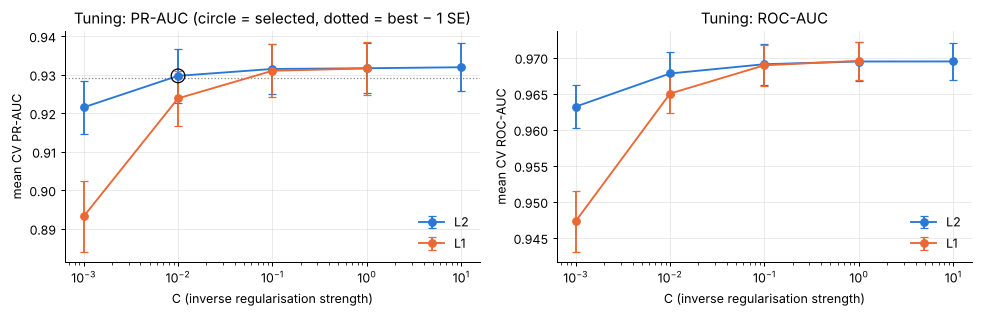

In [4]:
# One-standard-error rule (Hastie, Tibshirani & Friedman): among models whose mean PR-AUC is within
# 1 SE of the best, take the most strongly regularised one (smallest C; L2 preferred on ties).
top = tune.iloc[0]
se = top.PR_AUC_sd / np.sqrt(N_FOLDS)
cands = tune[tune.PR_AUC >= top.PR_AUC - se].sort_values(["C", "penalty"], ascending=[True, False])
best = cands.iloc[0]
BEST_L1 = 1.0 if best.penalty == "L1" else 0.0
BEST_C = float(best.C)
print(f"Best mean PR-AUC: {top.penalty} C={top.C} ({top.PR_AUC:.4f}); 1 SE = {se:.4f} -> cut-off {top.PR_AUC - se:.4f}")
print("Candidates within 1 SE:", [(r.penalty, r.C) for r in cands.itertuples()])
print(f"Selected (1-SE rule): {best.penalty}, C = {BEST_C}  (mean CV PR-AUC {best.PR_AUC:.4f} ± {best.PR_AUC_sd:.4f})")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for pen, c in [("L2", C_HC), ("L1", C_LK)]:
    t = tune[tune.penalty == pen].sort_values("C")
    ax[0].errorbar(t.C, t.PR_AUC, yerr=t.PR_AUC_sd, marker="o", color=c, label=pen, capsize=3)
    ax[1].errorbar(t.C, t.ROC_AUC, yerr=t.ROC_AUC_sd, marker="o", color=c, label=pen, capsize=3)
for a, m in zip(ax, ["PR-AUC", "ROC-AUC"]):
    a.set_xscale("log"); a.set_xlabel("C (inverse regularisation strength)"); a.set_ylabel(f"mean CV {m}"); a.legend(frameon=False)
ax[0].axhline(top.PR_AUC - se, color="#888780", ls=":", lw=1); ax[0].scatter([BEST_C], [best.PR_AUC], s=120, facecolors="none", edgecolors="black", zorder=4)
ax[0].set_title("Tuning: PR-AUC (circle = selected, dotted = best − 1 SE)"); ax[1].set_title("Tuning: ROC-AUC")
plt.tight_layout(); savefig("D2_tuning_curves"); plt.show()

## D3. Class-imbalance handling (at the selected C / penalty)
Three options, each applied **only to the training part of every fold**:
* `none`: plain LR.
* `balanced`: class weights inversely proportional to class frequency (leukemia errors cost 2× more here).
* `smote`: synthetic leukemia records created between neighbouring leukemia records until classes are 1:1 (own implementation of standard SMOTE, `lr_pipeline.smote`).

In [5]:
imb_rows, oof_by_imb = [], {}
for imb in IMBALANCE_OPTIONS:
    m = LRScreen(features=FEATURE_SET, log_features=LOG_FEATURES, C=BEST_C, l1_ratio=BEST_L1, imbalance=imb)
    p = oof_predict(m, X, y, folds); oof_by_imb[imb] = p
    a = np.array([(roc_auc_score(y.iloc[te], p[te]), average_precision_score(y.iloc[te], p[te]),
                   spec_at_recall(y.iloc[te], p[te], TARGET_RECALL), metrics_at(y.iloc[te], p[te], 0.5)["recall"]) for _, te in folds])
    imb_rows.append({"imbalance": imb, "ROC_AUC": a[:, 0].mean(), "PR_AUC": a[:, 1].mean(),
                     f"spec@recall{TARGET_RECALL:.2f}": a[:, 2].mean(), "recall@0.5": a[:, 3].mean(),
                     "threshold for target recall": threshold_for_recall(y, p, TARGET_RECALL)})
imb_tab = pd.DataFrame(imb_rows).set_index("imbalance")
imb_tab.to_csv(TAB_DIR / "D3_imbalance_comparison.csv")
imb_tab.round(4)

,ROC_AUC,PR_AUC,spec@recall0.90,recall@0.5,threshold for target recall
imbalance,,,,,
none,0.9675,0.9309,0.9308,0.8513,0.3437
balanced,0.9678,0.9297,0.9314,0.9026,0.5108
smote,0.9680,0.9300,0.9309,0.9015,0.5076


**Reading (D3).** The three options give practically the **same ROC-AUC, PR-AUC and specificity at 90% recall**. Class weights and SMOTE mainly **shift the predicted probabilities upwards**: recall at the default 0.5 cut-off rises, and the threshold needed for 90% recall moves.
Because we choose the threshold explicitly for recall anyway, the imbalance method matters little for a linear model. We keep **class weighting (`balanced`)**: it equals SMOTE here, adds no synthetic patients, and is deterministic.

In [6]:
IMBALANCE = "balanced"

## D4. Recall-based threshold selection (on out-of-fold predictions)
The OOF prediction for every development record comes from a model that did **not** train on it. On these pooled OOF scores we pick the **highest threshold with recall ≥ 0.90**, i.e. the fewest false alarms at that recall.
The threshold is then **frozen** and used unchanged on every validation/test hospital.

Chosen threshold: 0.5108  (target recall 0.9)


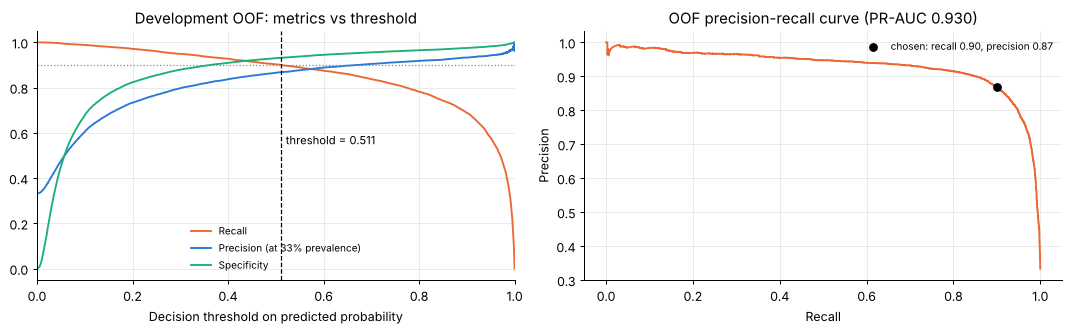

In [7]:
oof = oof_by_imb[IMBALANCE]
THR = threshold_for_recall(y, oof, TARGET_RECALL)
print(f"Chosen threshold: {THR:.4f}  (target recall {TARGET_RECALL})")
pr, rc, th = precision_recall_curve(y, oof)
fpr, tpr, th_roc = roc_curve(y, oof)
spec_curve = 1 - fpr
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(th, rc[:-1], color=C_LK, label="Recall"); ax[0].plot(th, pr[:-1], color=C_HC, label="Precision (at 33% prevalence)")
ax[0].plot(th_roc[1:], spec_curve[1:], color="#1baf7a", label="Specificity")
ax[0].axvline(THR, color="black", ls="--", lw=1); ax[0].axhline(TARGET_RECALL, color="#888780", ls=":", lw=1)
ax[0].text(THR + 0.01, 0.55, f"threshold = {THR:.3f}", fontsize=9)
ax[0].set_xlabel("Decision threshold on predicted probability"); ax[0].set_xlim(0, 1); ax[0].legend(frameon=False, fontsize=8, loc="lower center")
ax[0].set_title("Development OOF: metrics vs threshold")
ax[1].plot(rc, pr, color=C_LK); m = metrics_at(y, oof, THR)
ax[1].scatter([m["recall"]], [m["precision"]], color="black", zorder=3, label=f"chosen: recall {m['recall']:.2f}, precision {m['precision']:.2f}")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title(f"OOF precision-recall curve (PR-AUC {average_precision_score(y, oof):.3f})")
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); savefig("D4_threshold_selection"); plt.show()

In [8]:
# CV results per fold at the frozen threshold (proposal: "results on the cross-validation folds")
cv_rows = [{"fold": k + 1, **metrics_at(y.iloc[te], oof[te], THR)} for k, (_, te) in enumerate(folds)]
cv_tab = pd.DataFrame(cv_rows).set_index("fold")
cols = ["recall", "precision", "F1", "specificity", "ROC_AUC", "PR_AUC"]
cv_summary = pd.concat([cv_tab[cols], cv_tab[cols].agg(["mean", "std"])])
cv_summary.to_csv(TAB_DIR / "D4_cv_fold_results.csv")
cv_summary.round(4)

,recall,precision,F1,specificity,ROC_AUC,PR_AUC
1,0.9081,0.8666,0.8868,0.9301,0.9669,0.9282
2,0.8947,0.8597,0.8769,0.9270,0.9663,0.9226
3,0.9042,0.8773,0.8905,0.9368,0.9721,0.9381
4,0.8981,0.8699,0.8838,0.9329,0.9693,0.9355
5,0.8952,0.8658,0.8802,0.9306,0.9644,0.9239
mean,0.9000,0.8679,0.8837,0.9315,0.9678,0.9297
std,0.0059,0.0064,0.0054,0.0036,0.0030,0.0069


## D5. Final model: fit on all development data, evaluate on unseen cohorts

In [9]:
final = LRScreen(features=FEATURE_SET, log_features=LOG_FEATURES, C=BEST_C, l1_ratio=BEST_L1, imbalance=IMBALANCE).fit(X, y)
joblib.dump({"model": final, "threshold": THR, "target_recall": TARGET_RECALL, "features": FEATURE_SET}, MODEL_DIR / "lr_final.joblib")
print("Saved models/lr_final.joblib")
print(f"Non-zero coefficients: {(final.coefficients() != 0).sum()} of {len(final.coefficients())} "
      f"({len(FEATURE_SET)} features + {len(final.coefficients()) - len(FEATURE_SET)} missing-indicators)")

ev = fe[fe.cohort != "development"].reset_index(drop=True)
ev["p"] = final.predict_proba(ev)[:, 1]
ev[["sample_id", "cohort", "site", "y", "p"]].to_csv(PRED_DIR / "lr_raw71_eval_predictions.csv.gz", index=False, compression="gzip")
pd.DataFrame({"sample_id": dev.sample_id, "fold": fold_id, "y": y, "p_oof": oof}).to_csv(PRED_DIR / "lr_raw71_oof_development.csv", index=False)

res = [{"cohort": "development (CV, OOF)", "site": "A+B+C", **metrics_at(y, oof, THR)}]
for coh in ["internal_validation", "external_validation", "real_world_test"]:
    g = ev[ev.cohort == coh]
    if coh != "real_world_test":
        for s, gs in g.groupby("site"):
            res.append({"cohort": coh, "site": s, **metrics_at(gs.y, gs.p, THR)})
    res.append({"cohort": coh, "site": "pooled", **metrics_at(g.y, g.p, THR)})
results = pd.DataFrame(res)
results.to_csv(TAB_DIR / "D5_lr_results_at_threshold.csv", index=False)
show = ["cohort", "site", "n", "prevalence_%", "recall", "precision", "F1", "specificity", "ROC_AUC", "PR_AUC", "TP", "FN", "FP", "TN"]
results[show].round(3)

Saved models/lr_final.joblib
Non-zero coefficients: 138 of 138 (71 features + 67 missing-indicators)


,cohort,site,n,prevalence_%,recall,precision,F1,specificity,ROC_AUC,PR_AUC,TP,FN,FP,TN
0,"development (CV, OOF)",A+B+C,26922,33.333,0.900,0.868,0.884,0.931,0.968,0.930,8077,897,1230,16718
1,internal_validation,A,59986,4.554,0.948,0.379,0.541,0.926,0.975,0.585,2589,143,4242,53012
2,internal_validation,B,51227,1.821,0.892,0.205,0.334,0.936,0.963,0.380,832,101,3218,47076
3,internal_validation,C,100398,4.137,0.866,0.266,0.407,0.897,0.948,0.461,3598,555,9941,86304
4,internal_validation,pooled,211611,3.695,0.898,0.287,0.435,0.915,0.962,0.491,7019,799,17401,186392
5,external_validation,D,30156,4.391,0.918,0.234,0.373,0.862,0.954,0.526,1216,108,3976,24856
6,external_validation,E,94318,2.699,0.878,0.266,0.409,0.933,0.965,0.521,2235,311,6152,85620
7,external_validation,F,20179,4.901,0.875,0.396,0.545,0.931,0.964,0.563,865,124,1320,17870
8,external_validation,G,4970,18.612,0.853,0.557,0.674,0.845,0.912,0.638,789,136,628,3417
9,external_validation,pooled,149623,3.866,0.883,0.297,0.445,0.916,0.960,0.529,5105,679,12076,131763


For reference, the same model at the **default 0.5 threshold**. Because class weights already rebalance the classes, 0.5 is close to the recall-tuned threshold here.
Without class weights the 0.5 cut-off would give clearly lower recall (see D3, `none`: recall@0.5 ≈ 0.86).

In [10]:
res05 = [{"cohort": "development (CV, OOF)", "site": "A+B+C", **metrics_at(y, oof, 0.5)}]
for coh in ["internal_validation", "external_validation", "real_world_test"]:
    g = ev[ev.cohort == coh]; res05.append({"cohort": coh, "site": "pooled", **metrics_at(g.y, g.p, 0.5)})
r05 = pd.DataFrame(res05); r05.to_csv(TAB_DIR / "D5_lr_results_at_0.5.csv", index=False)
r05[["cohort", "site", "recall", "precision", "specificity", "flagged_%"]].round(3)

,cohort,site,recall,precision,specificity,flagged_%
0,"development (CV, OOF)",A+B+C,0.903,0.866,0.930,34.752
1,internal_validation,pooled,0.900,0.283,0.912,11.762
2,external_validation,pooled,0.886,0.293,0.914,11.703
3,real_world_test,pooled,0.937,0.311,0.915,11.790


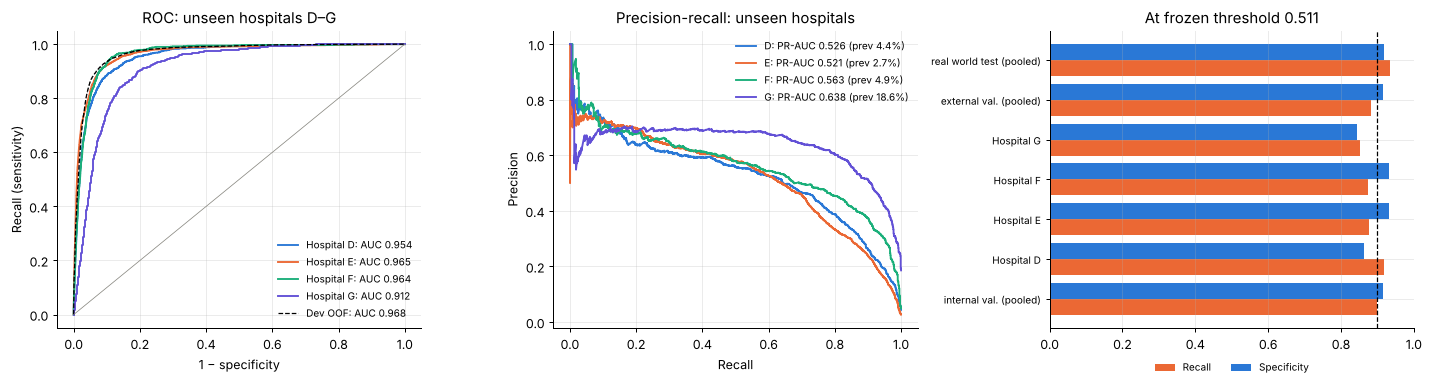

In [11]:
ext = ev[ev.cohort == "external_validation"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for s, g in ext.groupby("site"):
    f_, t_, _ = roc_curve(g.y, g.p); ax[0].plot(f_, t_, color=SITE_COL[s], label=f"Hospital {s}: AUC {roc_auc_score(g.y, g.p):.3f}")
    p_, r_, _ = precision_recall_curve(g.y, g.p)
    ax[1].plot(r_, p_, color=SITE_COL[s], label=f"{s}: PR-AUC {average_precision_score(g.y, g.p):.3f} (prev {100*g.y.mean():.1f}%)")
f_, t_, _ = roc_curve(y, oof); ax[0].plot(f_, t_, color="black", ls="--", lw=1, label=f"Dev OOF: AUC {roc_auc_score(y, oof):.3f}")
ax[0].plot([0, 1], [0, 1], color="#888780", lw=.6)
ax[0].set_xlabel("1 − specificity"); ax[0].set_ylabel("Recall (sensitivity)"); ax[0].set_title("ROC: unseen hospitals D–G"); ax[0].legend(frameon=False, fontsize=8)
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall: unseen hospitals"); ax[1].legend(frameon=False, fontsize=8)
r = results[results.site.isin(list("DEFG")) | (results.site == "pooled")].copy()
r["label"] = np.where(r.site == "pooled", r.cohort.str.replace("_", " ").str.replace("validation", "val.") + " (pooled)", "Hospital " + r.site)
r = r[r.cohort.isin(["external_validation", "internal_validation", "real_world_test"])]
yy = np.arange(len(r))
ax[2].barh(yy - .2, r.recall, height=.4, color=C_LK, label="Recall"); ax[2].barh(yy + .2, r.specificity, height=.4, color=C_HC, label="Specificity")
ax[2].set_yticks(yy); ax[2].set_yticklabels(r.label, fontsize=8); ax[2].axvline(TARGET_RECALL, color="black", ls="--", lw=1)
ax[2].set_xlim(0, 1); ax[2].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2); ax[2].set_title(f"At frozen threshold {THR:.3f}")
plt.tight_layout(); savefig("D5_external_validation"); plt.show()

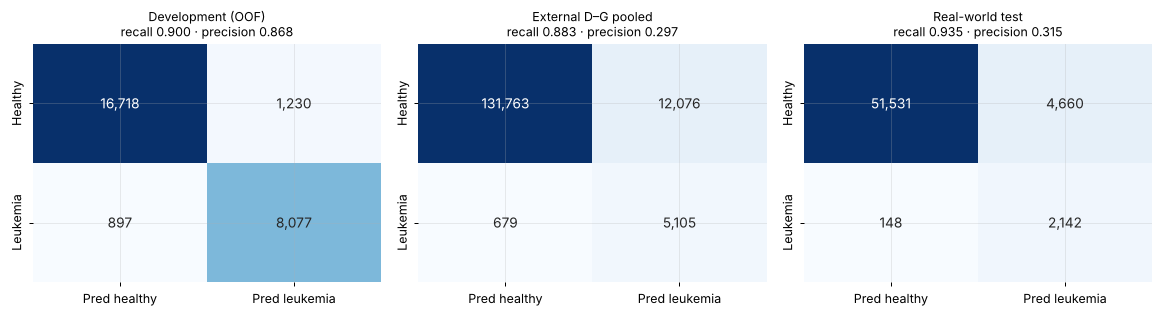

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, yt, pp) in zip(axes, [("Development (OOF)", y, oof), ("External D–G pooled", ext.y, ext.p),
                                     ("Real-world test", ev[ev.cohort == "real_world_test"].y, ev[ev.cohort == "real_world_test"].p)]):
    m = metrics_at(yt, pp, THR)
    cm = np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax, annot_kws={"fontsize": 11},
                xticklabels=["Pred healthy", "Pred leukemia"], yticklabels=["Healthy", "Leukemia"])
    ax.set_title(f"{name}\nrecall {m['recall']:.3f} · precision {m['precision']:.3f}", fontsize=10)
plt.tight_layout(); savefig("D5_confusion_matrices"); plt.show()

**Reading (D5).**
* **Discrimination transfers well to unseen hospitals.** ROC-AUC is 0.954–0.965 at hospitals D, E and F (development CV: 0.968). It is lower at **hospital G (0.912)**, a small site with an unusual 18.6% prevalence.
* **The frozen threshold gives slightly lower recall away from home.** It was set for 90% recall in CV. Pooled over the unseen hospitals it catches **88.3%** of leukemia cases (D 91.8%, E 87.8%, F 87.5%, G 85.3%), with specificity 0.85–0.93.
  Internal hospital C (86.6%) shows the same drift. **A site-specific threshold re-check is advisable before local deployment.**
* **Precision is low at real prevalence, as expected.** At 2.7–4.9% prevalence roughly **1 in 3–4 flagged patients has leukemia** (precision 0.23–0.40; G 0.56), and about 12% of all CBCs are flagged.
  PR-AUC falls from 0.93 (33% prevalence) to 0.52–0.64. That is still a **12–19× lift** over the no-skill baseline, which equals the prevalence. For a screening aid that triggers a smear review, this trade-off is acceptable but should be stated.
* The real-world test file behaves like the internal cohorts (recall 0.935, specificity 0.917).

## D6. Summary: Logistic Regression results

In [13]:
ex = results[(results.cohort == "external_validation") & (results.site == "pooled")].iloc[0]
cvm = cv_tab[cols].mean()
print(f"Model: LR, {best.penalty} penalty, C={BEST_C}, class weights, {len(FEATURE_SET)} raw features (+ missing indicators), threshold {THR:.3f} (OOF recall ≥ {TARGET_RECALL})")
print(f"CV (5-fold, development): ROC-AUC {cvm.ROC_AUC:.3f}, PR-AUC {cvm.PR_AUC:.3f}, recall {cvm.recall:.3f}, specificity {cvm.specificity:.3f}")
print(f"Unseen hospitals D–G pooled (n={ex.n:,}, prevalence {ex['prevalence_%']:.1f}%): ROC-AUC {ex.ROC_AUC:.3f}, PR-AUC {ex.PR_AUC:.3f}, "
      f"recall {ex.recall:.3f}, specificity {ex.specificity:.3f}, precision {ex.precision:.3f}")
for _, r_ in results[results.cohort == "external_validation"].iterrows():
    if r_.site != "pooled":
        print(f"   Hospital {r_.site}: recall {r_.recall:.3f}, specificity {r_.specificity:.3f}, ROC-AUC {r_.ROC_AUC:.3f}, PR-AUC {r_.PR_AUC:.3f} (prev {r_['prevalence_%']:.1f}%)")

Model: LR, L2 penalty, C=0.01, class weights, 71 raw features (+ missing indicators), threshold 0.511 (OOF recall ≥ 0.9)
CV (5-fold, development): ROC-AUC 0.968, PR-AUC 0.930, recall 0.900, specificity 0.931
Unseen hospitals D–G pooled (n=149,623, prevalence 3.9%): ROC-AUC 0.960, PR-AUC 0.529, recall 0.883, specificity 0.916, precision 0.297
   Hospital D: recall 0.918, specificity 0.862, ROC-AUC 0.954, PR-AUC 0.526 (prev 4.4%)
   Hospital E: recall 0.878, specificity 0.933, ROC-AUC 0.965, PR-AUC 0.521 (prev 2.7%)
   Hospital F: recall 0.875, specificity 0.931, ROC-AUC 0.964, PR-AUC 0.563 (prev 4.9%)
   Hospital G: recall 0.853, specificity 0.845, ROC-AUC 0.912, PR-AUC 0.638 (prev 18.6%)
